# FAKE NEWS CLASSIFICATION USING LSTM

# DOWNLOAD AND LOAD DATASET

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import pandas as pd

import warnings
warnings.filterwarnings('ignore')

In [2]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")


In [3]:
# Check the shapes of the loaded DataFrames
print("Shape of train dataset:", train.shape)
print("Shape of test dataset:", test.shape)

Shape of train dataset: (20800, 5)


In [4]:
train.head()

,id,title,author,text,label
0,0,House Dem Aide: We Didn’t Even See Comey’s Let...,Darrell Lucus,House Dem Aide: We Didn’t Even See Comey’s Let...,1
1,1,"FLYNN: Hillary Clinton, Big Woman on Campus - ...",Daniel J. Flynn,Ever get the feeling your life circles the rou...,0
2,2,Why the Truth Might Get You Fired,Consortiumnews.com,"Why the Truth Might Get You Fired October 29, ...",1
3,3,15 Civilians Killed In Single US Airstrike Hav...,Jessica Purkiss,Videos 15 Civilians Killed In Single US Airstr...,1
4,4,Iranian woman jailed for fictional unpublished...,Howard Portnoy,Print \nAn Iranian woman has been sentenced to...,1


In [5]:
test.head()

,id,title,author,text
0,20800,"Specter of Trump Loosens Tongues, if Not Purse...",David Streitfeld,"PALO ALTO, Calif. — After years of scorning..."
1,20801,Russian warships ready to strike terrorists ne...,NaN,Russian warships ready to strike terrorists ne...
2,20802,#NoDAPL: Native American Leaders Vow to Stay A...,Common Dreams,Videos #NoDAPL: Native American Leaders Vow to...
3,20803,"Tim Tebow Will Attempt Another Comeback, This ...",Daniel Victor,"If at first you don’t succeed, try a different..."
4,20804,Keiser Report: Meme Wars (E995),Truth Broadcast Network,42 mins ago 1 Views 0 Comments 0 Likes 'For th...


# DISTRIBUTION PLOT ON TARGET VARIABLE

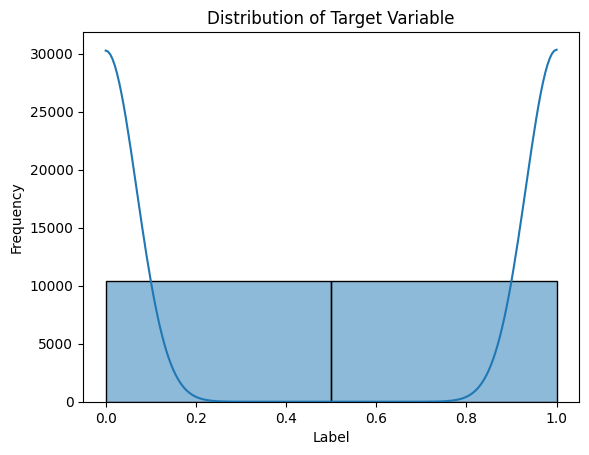

In [6]:
# Create a distribution plot for the target variable train['label']
sns.histplot(data=train, x='label', bins=2, kde=True)  # Assuming label is binary
plt.title('Distribution of Target Variable')
plt.xlabel('Label')
plt.ylabel('Frequency')
plt.show()

# DATA PREPROCESSING

In [7]:
def data_preprocessing(df):
  print(df.shape)
  print('\n', "+"*50 ,'\n')
  print("Data Information")
  print(df.info())
  print('\n', "+"*50 ,'\n')
  print("Data Null Values")
  print(df.isnull().sum())
  df = df.dropna()
  print("Data Null Values after Dropna")
  print(df.isnull().sum())
  print('\n', "+"*50 ,'\n')
  print("Duplicate values count")
  print('\n', "+"*50 ,'\n')
  print(df.duplicated().sum())
  print(df.shape)
  return df

In [8]:
train1 = data_preprocessing(train)

(20800, 5)

 ++++++++++++++++++++++++++++++++++++++++++++++++++ 

Data Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20800 entries, 0 to 20799
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      20800 non-null  int64 
 1   title   20242 non-null  object
 2   author  18843 non-null  object
 3   text    20761 non-null  object
 4   label   20800 non-null  int64 
dtypes: int64(2), object(3)
memory usage: 812.6+ KB
None

 ++++++++++++++++++++++++++++++++++++++++++++++++++ 

Data Null Values
id           0
title      558
author    1957
text        39
label        0
dtype: int64
Data Null Values after Dropna
id        0
title     0
author    0
text      0
label     0
dtype: int64

 ++++++++++++++++++++++++++++++++++++++++++++++++++ 

Duplicate values count

 ++++++++++++++++++++++++++++++++++++++++++++++++++ 

0
(18285, 5)


# TEXT CLEANING

- lowering the text
- removing the special symbols
- removing the tags [\n etc]
- Removing the Web tags [www. @ etc]
- removing numbers/figures

In [9]:
import re
import string
import warnings
warnings.filterwarnings('ignore')

def text_cleaning(df):
  try:
      df['text']= df['text'].str.lower()
      print("Data Lower case successfull")
      # Remove HTML tags from the text in the 'text' column
      df['text'] = df['text'].apply(lambda x: re.sub(r'<[^>]*>', '', x))
      print("data html tags removed successfull")
      df['text'] = df['text'].apply(lambda x: re.sub(r'\d+', '', x))
      print("data Numbers removed successfull")
      df['text'] = df['text'].apply(lambda x: re.sub(r'[\n\t]', '', x))
      print("data TagLines/Newlines removed successfull")
      df['text'] = df['text'].apply(lambda x: re.sub(r'[\'\"\-]', '', x))
      print("data Double quote, single quote hypen removed successfull")
      df['text'] = df['text'].apply(lambda x: re.sub(r'[’‘“”]', '', x))

      # remove http, www log words with sigle char wwwaaaaayyyyy downhillthe etc
      df['text'] = df['text'].apply(lambda x: re.sub(r'(www\w*|http\w*|\\|\b\w*(\w)\2{5,}\w*\b)' , '', x))
      print("data website tags removed successfull")
      # Punctuation removal
      df['text'] = df['text'].apply(lambda x: "".join(char for char in x if char not in string.punctuation))
      print("data punctuation removed successfull")
      print('\n', "+"*50 ,'\n')
      print("Data Cleaning is completed Successfully")
      return df
  except Exception as e:
      raise e

In [10]:
df1 = text_cleaning(train1)

Data Lower case successfull
data html tags removed successfull
data Numbers removed successfull
data TagLines/Newlines removed successfull
data Double quote, single quote hypen removed successfull
data website tags removed successfull
data punctuation removed successfull

 ++++++++++++++++++++++++++++++++++++++++++++++++++ 

Data Cleaning is completed Successfully


In [11]:
df2 = df1.copy()

In [12]:
def replace_text(df):
    # Iterate over DataFrame rows
    for index, row in df.iterrows():
        # Split the text into words and count the number of words
        text_words = row['text'].split()
        num_words = len(text_words)

        # Check if the number of words is less than 5
        if num_words > 100:

            df.at[index, 'text'] = ' '.join(text_words[:100])

    return df

In [13]:
df5 = replace_text(df2)

In [14]:
df5

,id,title,author,text,label
0,0,House Dem Aide: We Didn’t Even See Comey’s Let...,Darrell Lucus,house dem aide we didnt even see comeys letter...,1
1,1,"FLYNN: Hillary Clinton, Big Woman on Campus - ...",Daniel J. Flynn,ever get the feeling your life circles the rou...,0
2,2,Why the Truth Might Get You Fired,Consortiumnews.com,why the truth might get you fired october the ...,1
3,3,15 Civilians Killed In Single US Airstrike Hav...,Jessica Purkiss,videos civilians killed in single us airstrike...,1
4,4,Iranian woman jailed for fictional unpublished...,Howard Portnoy,print an iranian woman has been sentenced to s...,1
...,...,...,...,...,...
20795,20795,Rapper T.I.: Trump a ’Poster Child For White S...,Jerome Hudson,rapper t i unloaded on black celebrities who m...,0
20796,20796,"N.F.L. Playoffs: Schedule, Matchups and Odds -...",Benjamin Hoffman,when the green bay packers lost to the washing...,0
20797,20797,Macy’s Is Said to Receive Takeover Approach by...,Michael J. de la Merced and Rachel Abrams,the macys of today grew from the union of seve...,0
20798,20798,"NATO, Russia To Hold Parallel Exercises In Bal...",Alex Ansary,nato russia to hold parallel exercises in balk...,1


In [15]:
x= df5['text']

In [16]:
y= df5['label']

 ## TOKENIZE AND REMOVE STOPWORDS

In [17]:
import pandas as pd
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
# Download stopwords if not already downloaded
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')


[nltk_data] Downloading package punkt to
[nltk_data]     ~\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     ~\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     ~\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

This function tokenizes, removes stopwords, and lemmatizes text data.

- Initialize a WordNetLemmatizer object named lemmatizer for lemmatization.
- Create an empty list named tokenized_X to store the tokenized and processed text data.
- Create a set of stopwords for the English language using the stopwords.words('english') function.
- Iterate over each text in the input data X.
  - Tokenize the text using the word_tokenize function from the NLTK library.
  - Remove stopwords and lemmatize each word using list comprehension.
  - Join the filtered and lemmatized words into a single string.
  - Append the processed text to the tokenized_X list.
- Return the tokenized and processed text data stored in tokenized_X.


In [18]:
%pip install nltk -q
%pip install spacy -q
print(nltk.__version__)


Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
3.8.1


In [19]:
import spacy
nlp = spacy.load("en_core_web_sm")

In [20]:
import nltk
nltk.data.path.append("/path/to/nltk_data")

In [21]:
import spacy

# Load spaCy English model
nlp = spacy.load("en_core_web_sm")

def tokenize_remove_stopwords_lemmatize(X):
    tokenized_X = []

    for text in X:
        # Process the text with spaCy
        doc = nlp(text)
        
        # Lemmatize and remove stopwords
        filtered_words = [token.lemma_.lower() for token in doc if not token.is_stop]
        
        # Join the filtered words
        filtered_text = ' '.join(filtered_words)
        
        tokenized_X.append(filtered_text)

    return tokenized_X

In [22]:
tokenized_X = tokenize_remove_stopwords_lemmatize(x)


# ONE HOT ENCODING

In [23]:
from tensorflow.keras.preprocessing.text import one_hot

In [24]:
vocab_size = 20000

In [25]:
def onehotencoding(tokenized_X, vocab_size):
    onehot_rep = [one_hot(word, vocab_size) for word in tokenized_X]
    return onehot_rep

In [26]:
onehot_rep_x = onehotencoding(tokenized_X , vocab_size)

In [27]:
len(tokenized_X[0].split())

58

In [28]:
len(onehot_rep_x[0])

58

# EMBEDDING REPRESENTATION

In [29]:
sent_length = 120

In [30]:
from tensorflow.keras.layers import Embedding
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [31]:
def ebedded(text , sent_length):
  ebedded_doc= pad_sequences(text, padding='pre', maxlen = sent_length)
  return ebedded_doc

In [32]:
embedded_X = ebedded(onehot_rep_x, sent_length)

In [33]:
embedded_X

array([[    0,     0,     0, ...,  9277, 11625,  1023],
       [    0,     0,     0, ...,  1714, 12323,  3065],
       [    0,     0,     0, ...,   935,  4297,  4614],
       ...,
       [    0,     0,     0, ..., 17989, 11794,  2936],
       [    0,     0,     0, ...,  7480, 17612, 16174],
       [    0,     0,     0, ..., 15565,  9936, 12407]])

# Feature Creation for Each vector

In [34]:
features = 40

In [35]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM
from tensorflow.keras.layers import Dense


In [36]:
def model(vocab_size,features,sent_length):
  model = Sequential()
  model.add(Embedding(vocab_size, features , input_length = sent_length))
  model.add(LSTM(100))
  model.add(Dense(1, activation = 'sigmoid'))
  model.compile(loss = 'binary_crossentropy', optimizer = 'adam' , metrics=['accuracy'])
  print(model.summary())
  return model

In [37]:
model = model(vocab_size,features,sent_length)



Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding (Embedding)       (None, 120, 40)           800000    
                                                                 
 lstm (LSTM)                 (None, 100)               56400     
                                                                 
 dense (Dense)               (None, 1)                 101       
                                                                 
Total params: 856501 (3.27 MB)
Trainable params: 856501 (3.27 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________
None


# DATA SPLITING AND MAKE IT READY FOR X , Y

In [38]:
y.shape

(18285,)

In [39]:
X = embedded_X

In [40]:
print("X shape",X.shape)
print("y Shape",y.shape)

X shape (18285, 120)
y Shape (18285,)


# TRAIN TEST SPLIT

In [41]:
from sklearn.model_selection import train_test_split

X_train , X_test, y_train, y_test = train_test_split(X, y, test_size=.25, random_state=123)

In [42]:
print("X_train shape",X_train.shape)
print("X_test shape",X_test.shape)
print("y_train shape",y_train.shape)
print("y_test shape",y_test.shape)

X_train shape (13713, 120)
X_test shape (4572, 120)
y_train shape (13713,)
y_test shape (4572,)


#MODEL TRAINING

In [43]:
model.fit(X_train, y_train, validation_data =(X_test, y_test), epochs =10 , batch_size=64)

Epoch 1/10


215/215 [==============================] - 16s 64ms/step - loss: 0.4053 - accuracy: 0.8077 - val_loss: 0.2866 - val_accuracy: 0.8867
Epoch 2/10
215/215 [==============================] - 13s 61ms/step - loss: 0.1452 - accuracy: 0.9492 - val_loss: 0.2414 - val_accuracy: 0.9158
Epoch 3/10
215/215 [==============================] - 13s 62ms/step - loss: 0.0560 - accuracy: 0.9838 - val_loss: 0.2738 - val_accuracy: 0.9066
Epoch 4/10
215/215 [==============================] - 13s 61ms/step - loss: 0.0229 - accuracy: 0.9945 - val_loss: 0.3417 - val_accuracy: 0.9077
Epoch 5/10
215/215 [==============================] - 13s 61ms/step - loss: 0.0237 - accuracy: 0.9929 - val_loss: 0.3668 - val_accuracy: 0.9053
Epoch 6/10
215/215 [==============================] - 13s 62ms/step - loss: 0.0108 - accuracy: 0.9968 - val_loss: 0.3484 - val_accuracy: 0.9073
Epoch 7/10
215/215 [==============================] - 13s 62ms/step - loss: 0.0084 - accuracy: 0.9982 - val_loss: 0.4006 - val_accurac

## OBSERVATION

- accuracy: 0.9959
- val_accuracy: 0.9094

In [44]:
history = model.fit(X_train, y_train, validation_data =(X_test, y_test), epochs =10 , batch_size=64)
#modelLSTM with 100 neuron

Epoch 1/10
215/215 [==============================] - 14s 64ms/step - loss: 0.0063 - accuracy: 0.9988 - val_loss: 0.4785 - val_accuracy: 0.8965
Epoch 2/10
215/215 [==============================] - 13s 63ms/step - loss: 0.0029 - accuracy: 0.9996 - val_loss: 0.4944 - val_accuracy: 0.9055
Epoch 3/10
215/215 [==============================] - 14s 63ms/step - loss: 0.0011 - accuracy: 0.9998 - val_loss: 0.5800 - val_accuracy: 0.9121
Epoch 4/10
215/215 [==============================] - 13s 63ms/step - loss: 7.1500e-04 - accuracy: 0.9999 - val_loss: 0.6269 - val_accuracy: 0.9099
Epoch 5/10
215/215 [==============================] - 14s 64ms/step - loss: 6.5403e-04 - accuracy: 0.9999 - val_loss: 0.6392 - val_accuracy: 0.9101
Epoch 6/10
215/215 [==============================] - 14s 64ms/step - loss: 6.2634e-04 - accuracy: 0.9999 - val_loss: 0.6775 - val_accuracy: 0.9094
Epoch 7/10
215/215 [==============================] - 14s 65ms/step - loss: 5.9859e-04 - accuracy: 0.9999 - val_loss: 0.7015

# MODEL PREDICT

- Compute the accuracy score between the true labels (y_test) and the predicted labels (y_pred) using the accuracy_score function from sklearn.metrics.
- Compute the confusion matrix between the true labels (y_test) and the predicted labels (y_pred) using the confusion_matrix function from sklearn.metrics.
- Compute the classification report, including precision, recall, F1-score, and support, between the true labels (y_test) and the predicted labels (y_pred) using the classification_report function from sklearn.metrics.
- Print the computed accuracy score.
- Print a separator line for better readability.
- Print the computed confusion matrix.
- Print a separator line for better readability.
- Print the computed classification report.

In [45]:
y_pred = model.predict(X_test)

143/143 [==============================] - 3s 15ms/step


In [46]:
y_pred = np.where(y_pred > 0.5, 1,0)

In [47]:
from sklearn.metrics import accuracy_score , confusion_matrix, classification_report

In [48]:
def metrics_result(y_test, y_pred):
  accuracy = accuracy_score(y_test, y_pred)
  accuracy
  confusion = confusion_matrix(y_test, y_pred)
  classification  = classification_report(y_test, y_pred)
  print(accuracy)
  print('\n', "+"*50 ,'\n')
  print(confusion)
  print('\n', "+"*50 ,'\n')
  print(classification)

# Metrix Observations:

In [49]:
metrics_result(y_test, y_pred)

0.8926071741032371

 ++++++++++++++++++++++++++++++++++++++++++++++++++ 

[[2318  254]
 [ 237 1763]]

 ++++++++++++++++++++++++++++++++++++++++++++++++++ 

              precision    recall  f1-score   support

           0       0.91      0.90      0.90      2572
           1       0.87      0.88      0.88      2000

    accuracy                           0.89      4572
   macro avg       0.89      0.89      0.89      4572
weighted avg       0.89      0.89      0.89      4572



# MODEL EVALUTION

# Graph Observations:
- The accuracy plot shows that the model achieves near-perfect accuracy (99%) on the training dataset, indicating that it has learned the training data well. However, the accuracy on the testing dataset is around 90%, suggesting a slight drop in performance on unseen data, which could indicate overfitting.
- The loss plot shows a decreasing trend in both training and testing loss over epochs, which indicates that the model is learning and improving its performance. However, there may be some overfitting as the training loss continues to decrease while the testing loss stabilizes or increases slightly.

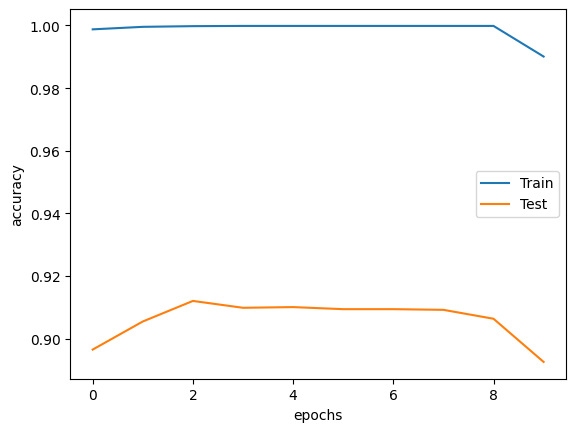

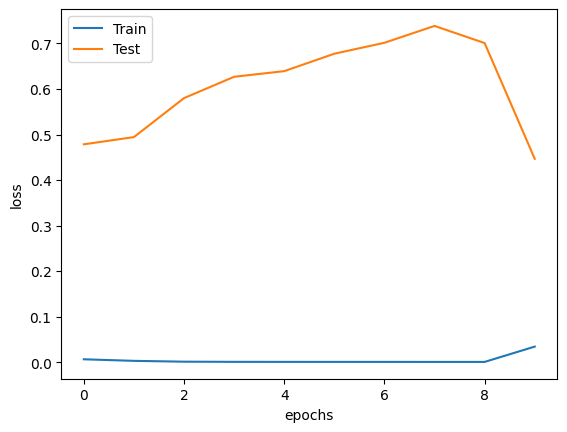

In [50]:
# Assuming you have trained your model and stored the history object as 'history'

# Plot accuracy
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.xlabel('epochs')
plt.ylabel('accuracy')
plt.legend(['Train', 'Test'])
plt.show()

# Plot loss
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.xlabel('epochs')
plt.ylabel('loss')
plt.legend(['Train', 'Test'])
plt.show()
